<a href="https://colab.research.google.com/github/edina-s/ADVANCED-CSS/blob/master/02_Eksplorativna_analiza_podatkov/notebooks/02_osamelci/B_osamelci.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detekcija in obravnava osamelcev — B: vaja (spletna trgovina)
**Akademija UI za poslovne aplikacije — Modul 1, popoldanski sklop**

Predavatelj je v zvezku `A_osamelci` postopek pokazal na telekomu.
Zdaj pregledate ekstremne vrednosti naročil spletne trgovine in predlagate obravnavo.

### Ponovitev
- **Osamelec**: vrednost, ki močno odstopa od ostalih. Lahko je
  - **napaka** — vrednost je nemogoča (vnos, prenos, napačna enota), ali
  - **veljaven ekstrem** — redka, a resnična vrednost.
- **Odkrivanje:** najprej graf (histogram, škatla z brki), nato **pravilo IQR**:
  kandidati so pod Q1 − 1,5 × IQR ali nad Q3 + 1,5 × IQR (= točke zunaj brkov).
- Pravilo IQR **ne pozna poslovanja** → dodamo **domenske omejitve** (npr. naročnina ≥ 0)
  in preverimo **povezane stolpce** iste stranke ali naročila.
- **Odzivi:** popravek iz preverjenega vira, označimo kot manjkajočo (`NaN`), odstranitev (z utemeljitvijo),
  omejevanje ali logaritem, ohranitev.
- **Osamelec ni nujno napaka; včasih je ravno najzanimivejši podatek.**

### Nastavitev okolja
Zaženite spodnjo celico (izberite jo in pritisnite **Shift + Enter**). Ničesar ne spreminjajte.
Celica deluje lokalno in v Google Colabu. Koda je skrita — odprete jo s klikom na celico.

In [1]:
#@title Nastavitev okolja (kliknite za prikaz kode)
import subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/valira-ai/ui-za-poslovne-aplikacije.git"

if "google.colab" in sys.modules:           # Google Colab: prenesemo gradivo z GitHuba
    KOREN = Path("/content/ui-za-poslovne-aplikacije")
    if not KOREN.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(KOREN)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plotnine>=0.15", "kagglehub"], check=True)
else:                                       # lokalno: poiščemo mapo, v kateri je utils/orodja.py
    KOREN = Path.cwd()
    while not (KOREN / "utils/orodja.py").exists() and KOREN != KOREN.parent:
        KOREN = KOREN.parent
sys.path.insert(0, str(KOREN))              # da Python najde utils/orodja.py
print("Gradivo je v:", KOREN)

Gradivo je v: /content/ui-za-poslovne-aplikacije


### Podatki
Funkcija `poskrbi_za_podatke()` iz `utils/orodja.py` ob prvem zagonu prenese podatke s Kaggla (~1 minuta)
in jih shrani v mapo `data/`. Kako to deluje, smo pokazali v zvezku `A_prvi_stik_s_podatki`.

In [2]:
from utils.orodja import poskrbi_za_podatke
DATA = poskrbi_za_podatke()

Prenašam abhinav89/telecom-customer s Kaggla ...
Using Colab cache for faster access to the 'telecom-customer' dataset.
Prenašam olistbr/brazilian-ecommerce s Kaggla ...
Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Podatki so pripravljeni v: /content/ui-za-poslovne-aplikacije/data


### Knjižnice in videz grafov
`pripravi_narocila` (zvezek `A_vizualizacija`), `histogram_in_skatla` (zvezek `A_vizualizacija`)
in `meje_iqr` (zvezek `A_osamelci`) uvozimo iz `utils/orodja.py`.

In [3]:
import numpy as np
import pandas as pd
from plotnine import *

from utils.orodja import nastavi_slog, MODRA, ORANZNA, ZELENA, SIVA, BARVE_ODHOD
from utils.orodja import pripravi_narocila, histogram_in_skatla, meje_iqr
nastavi_slog()      # enoten videz grafov (koda je v zvezku A_vizualizacija)

---
# Del B — Vaja: spletna trgovina
Ena vrstica = eno naročilo. Na vrhu celice zamenjate ime stolpca in celico ponovno zaženete (**Shift + Enter**).

In [4]:
narocila = pripravi_narocila(DATA)
narocila.describe().round(1)

,datum_nakupa,st_postavk,vrednost,postnina,teza_g,st_obrokov,dni_dostave,zamuda_dni,ocena
count,99441,98666.0,98666.0,98666.0,98666.0,99440.0,96476.0,96476.0,98673.0
mean,2017-12-31 08:43:12.776581120,1.1,137.8,22.8,2390.0,2.9,12.1,-11.9,4.1
min,2016-09-04 21:15:19,1.0,0.8,0.0,0.0,0.0,0.0,-147.0,1.0
25%,2017-09-12 14:46:19,1.0,45.9,13.8,300.0,1.0,6.0,-17.0,4.0
50%,2018-01-18 23:04:36,1.0,86.9,17.2,750.0,2.0,10.0,-12.0,5.0
75%,2018-05-04 15:42:16,1.0,149.9,24.0,2066.8,4.0,15.0,-7.0,5.0
max,2018-10-17 17:30:18,21.0,13440.0,1795.0,184400.0,24.0,209.0,188.0,5.0
std,NaN,0.5,210.6,21.7,4773.2,2.7,9.6,10.2,1.3


## B1. Poiščite kandidate
Poskusite: `"vrednost"` (z `LOG = True`), `"teza_g"`, `"postnina"`, `"dni_dostave"`, `"st_obrokov"`.
Pri `LOG = True` škatla računa brke na logaritmih, zato se ne ujemajo povsem z mejama IQR v izpisu.

**Vprašanje:** Koliko naročil označi pravilo IQR? So med njimi vrednosti 0? So to napake?

Meji IQR: od -110.1 do 305.9
Označenih: 7913 (8.0%)
Vrednosti = 0: 0   vrednosti < 0: 0


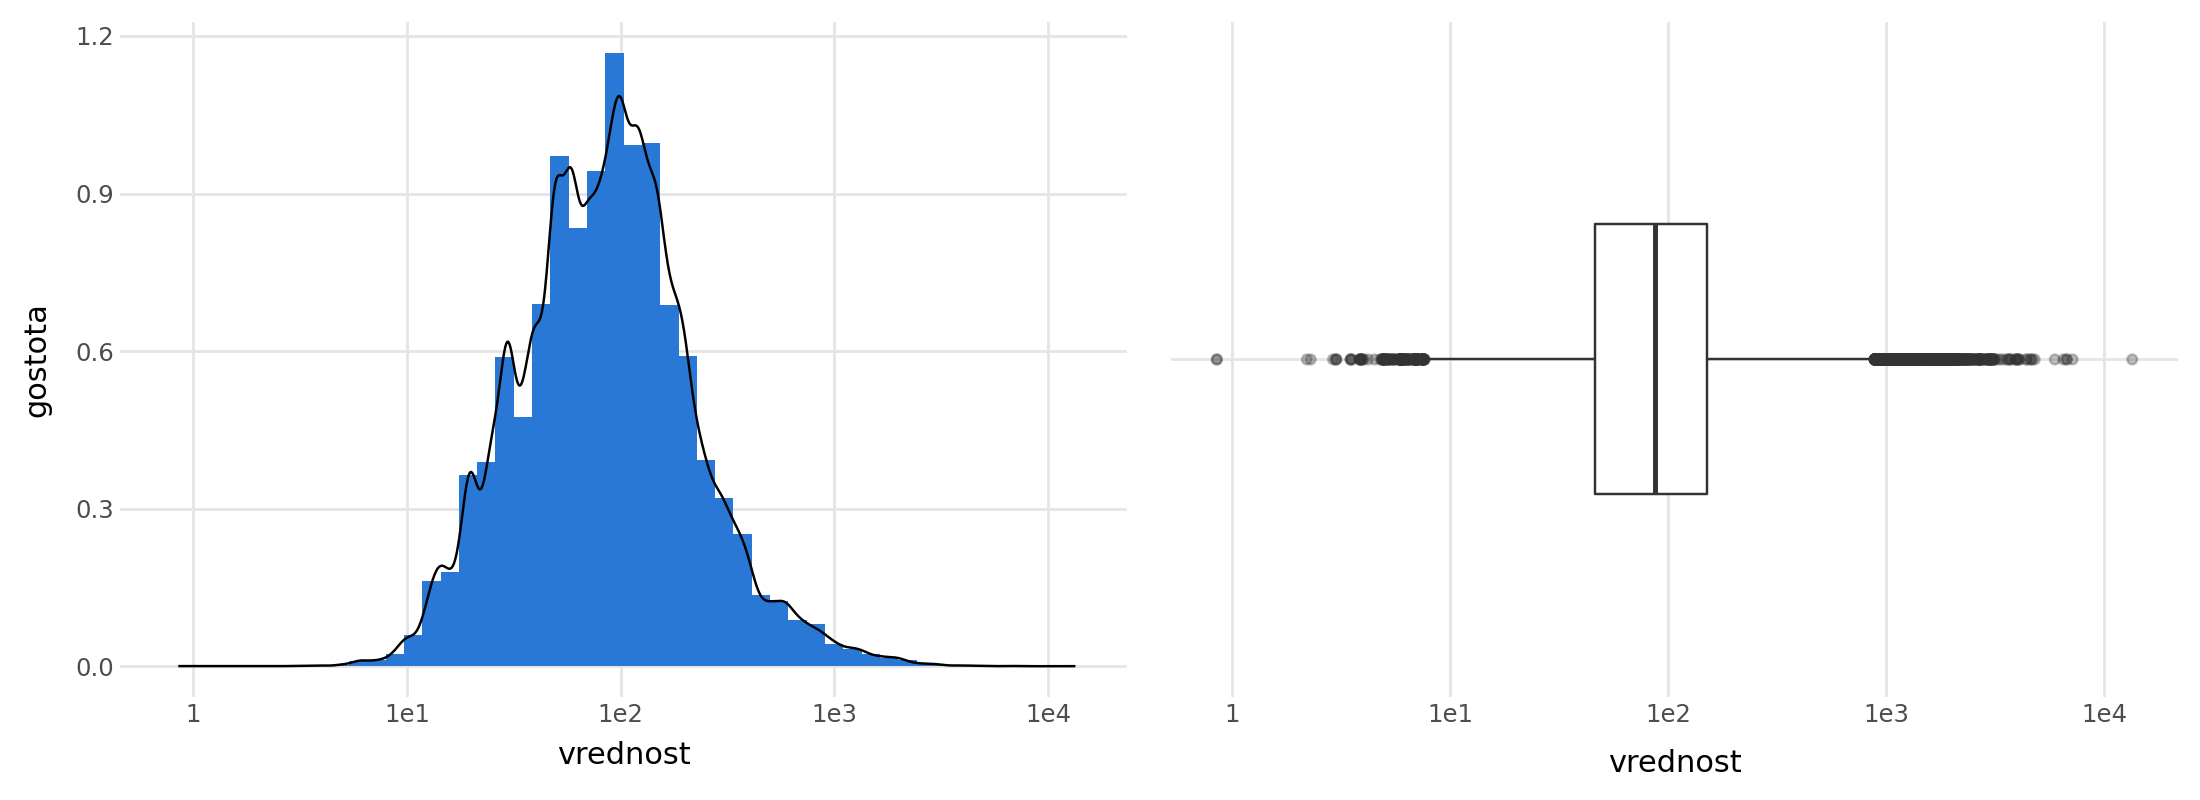

In [5]:
STOLPEC = "vrednost"          # ← zamenjajte
LOG = True                    # ← logaritemska os (samo za prikaz)

s = narocila[STOLPEC].dropna().astype(float)
spodaj, zgoraj = meje_iqr(s)
oznaceni = (s < spodaj) | (s > zgoraj)
print(f"Meji IQR: od {spodaj:.1f} do {zgoraj:.1f}")
print(f"Označenih: {oznaceni.sum()} ({oznaceni.mean():.1%})")
print(f"Vrednosti = 0: {(s == 0).sum()}   vrednosti < 0: {(s < 0).sum()}")

histogram_in_skatla(narocila, STOLPEC, log=LOG)

## B2. Poglejte najbolj ekstremna naročila
Preverite **povezane stolpce**: koliko postavk ima naročilo, kakšna je poštnina, kategorija, ocena kupca …

In [6]:
STOLPEC = "vrednost"          # ← zamenjajte

narocila.nlargest(8, STOLPEC)         # največje; za najmanjše: narocila.nsmallest(8, STOLPEC)

,order_id,datum_nakupa,status,zvezna_drzava,kategorija,st_postavk,vrednost,postnina,teza_g,nacin_placila,st_obrokov,dni_dostave,zamuda_dni,ocena
13390,03caa2c082116e1d31e67e9ae3700499,2017-09-29 15:24:52,delivered,RJ,fixed_telephony,8.0,13440.0,224.08,6000.0,credit_card,1.0,18.0,-6.0,1
66599,736e1922ae60d0d6a89247b851902527,2018-07-15 14:49:44,delivered,ES,fixed_telephony,4.0,7160.0,114.88,4400.0,boleto,1.0,11.0,-7.0,1
22171,0812eb902a67711a1cb742b3cdaa65ae,2017-02-12 20:37:36,delivered,MS,housewares,1.0,6735.0,194.31,30000.0,credit_card,8.0,18.0,-6.0,5
28326,fefacc66af859508bf1a7934eab1e97f,2018-07-25 18:10:17,delivered,ES,computers,1.0,6729.0,193.21,5660.0,boleto,1.0,20.0,5.0,<NA>
3508,f5136e38d1a14a4dbd87dff67da82701,2017-05-24 18:14:34,delivered,SP,art,1.0,6499.0,227.66,7400.0,boleto,1.0,11.0,-23.0,5
32322,2cc9089445046817a7539d90805e6e5a,2017-11-24 11:03:35,delivered,MG,agro_industry_and_commerce,6.0,5934.6,146.94,9000.0,boleto,1.0,19.0,-9.0,1
53352,a96610ab360d42a2e5335a3998b4718a,2017-04-01 15:58:40,delivered,RJ,small_appliances,1.0,4799.0,151.34,22600.0,credit_card,10.0,15.0,-15.0,5
40327,199af31afc78c699f0dbf71fb178d4d4,2017-04-18 18:50:13,delivered,SP,small_appliances,1.0,4690.0,74.34,30000.0,credit_card,8.0,18.0,-8.0,4


Ali so ekstremni časi dostave povezani z oceno kupca? `pd.cut` razdeli dneve v razrede, `groupby` izračuna povprečno oceno v vsakem.

dni_dostave  mean  count
      do 10  4.38  51842
      11–20  4.19  31673
      21–30  3.58   8307
      31–60  2.17   3735
     nad 60  2.17    273


/usr/local/lib/python3.13/dist-packages/plotnine/positions/position_stack.py:108: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


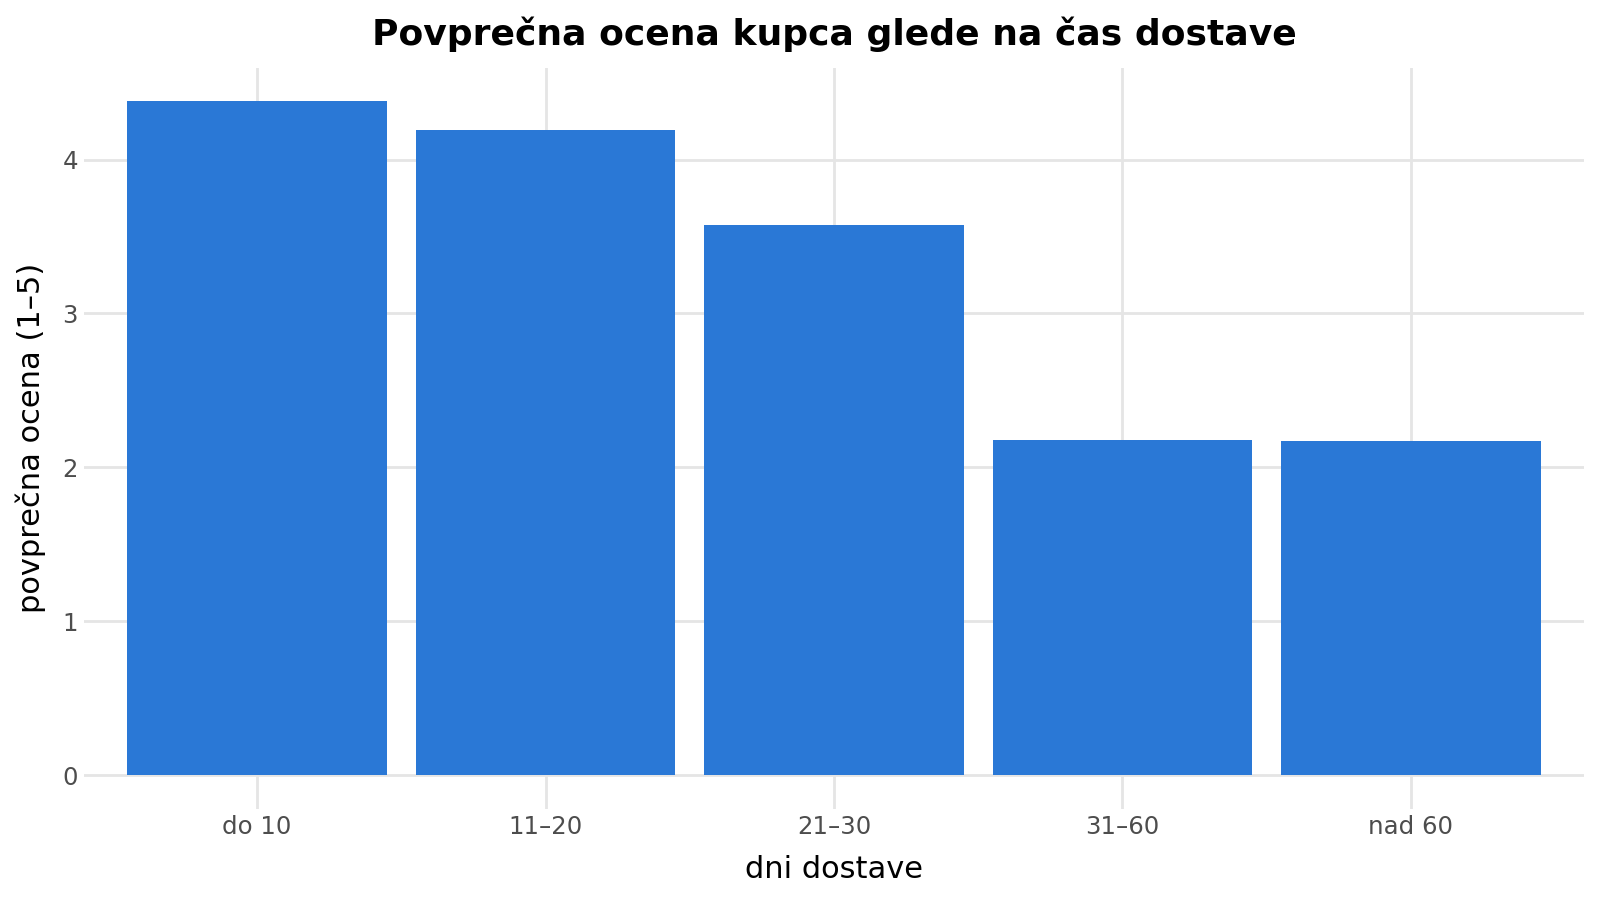

In [7]:
razredi = pd.cut(narocila["dni_dostave"], bins=[-1, 10, 20, 30, 60, 250],
                 labels=["do 10", "11–20", "21–30", "31–60", "nad 60"])
po_razredih = (narocila.groupby(razredi, observed=True)["ocena"]
               .agg(["mean", "count"]).reset_index())
print(po_razredih.round(2).to_string(index=False))

(ggplot(po_razredih, aes(x="dni_dostave", y="mean"))
 + geom_col(fill=MODRA)
 + labs(title="Povprečna ocena kupca glede na čas dostave", x="dni dostave", y="povprečna ocena (1–5)"))

## B3. Zapišite predlog
Dvakrat kliknite to celico in dopolnite za vsaj dva stolpca.

**Stolpec:** ...
**Napaka ali veljaven ekstrem? Zakaj?** ...
**Predlagana obravnava:** ...

**Za razpravo:** v teh podatkih negativnih vrednosti naročil ni. Če bi v stolpcu `vrednost` našli −120 BRL —
bi bila to napaka ali **vračilo**? Kako bi to preverili?

<details>
<summary><b>Rešitev (klikni)</b></summary>

Primer razmisleka (ne edini pravilni):

- **`vrednost`** — pravilo IQR označi ~8 % naročil (nad ~306 BRL). To so večinoma **veljavna** draga naročila
  (računalniki, telefonija, več postavk). Največje (13 440 BRL) ima 8 postavk, kategorija `fixed_telephony` — verjetno nakup podjetja.
  **Ohranimo.** Za model po potrebi `log1p`.
- **`teza_g`** — 22 naročil s težo **0 g**. Fizični izdelek ne more tehtati 0 g → napaka pri vnosu izdelka.
  **Označimo kot manjkajoče** (`mask`). Zelo težka naročila (100+ kg, pohištvo) so veljavna.
- **`postnina`** — 0 BRL pri ~340 naročilih. **Veljavno**: brezplačna dostava (akcija). Ohranimo.
- **`dni_dostave`** — do 209 dni. Možno (izgubljena pošiljka, zamuda), in poslovno **zelo zanimivo**: pri dostavi nad 30 dni
  je povprečna ocena ~2,2 (graf v B2). Ohranimo — to je ravno podatek, ki ga želimo videti.
- **`st_obrokov`** — 2 naročili z **0 obroki**. Plačilo ima vsaj en obrok → napaka. Označimo kot manjkajoče ali popravimo na 1.

**Negativna vrednost** je lahko napaka (minus pri vnosu) ali **vračilo / storno**. Preverimo v povezanih podatkih:
ali obstaja prvotno naročilo z enakim zneskom, kakšen je status naročila, kaj pravi računovodstvo.
Če gre za vračila, jih ne brišemo — za analizo prihodka jih potrebujemo.

</details>

---
### Za hitre
1. V telekomu ima ena stranka `stevilo_narocnin = 196`. Poglejte jo:
   `pd.read_csv(DATA / "telekom.csv").nlargest(3, "stevilo_narocnin")`. Napaka ali poslovni naročnik?
2. Koliko vsega prihodka trgovine prinesejo naročila, ki jih pravilo IQR označi pri `vrednost`?
   Namig: najprej `_, zgoraj = meje_iqr(narocila["vrednost"])`,
   nato `narocila.loc[narocila["vrednost"] > zgoraj, "vrednost"].sum() / narocila["vrednost"].sum()`